# Smart Traffic Intelligence System
## Phase 6: Model Evaluation and Comparison

### Objective
Evaluate and compare Random Forest and XGBoost models.

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- Macro F1-score
- Confusion Matrix
- Classification Report

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "models").exists():
    PROJECT_DIR = PROJECT_DIR.parent

MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "visualizations" / "reports"
CHART_DIR = PROJECT_DIR / "visualizations" / "charts"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

RF_PATH = MODEL_DIR / "accident_severity_random_forest.pkl"
XGB_PATH = MODEL_DIR / "accident_severity_xgboost.pkl"

print("Project directory:", PROJECT_DIR)
print("Random Forest available:", RF_PATH.exists())
print("XGBoost available:", XGB_PATH.exists())

Project directory: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project
Random Forest available: True
XGBoost available: False


In [3]:
if not RF_PATH.exists():
    raise FileNotFoundError(
        "Random Forest model not found. "
        "Run Cell 18 in Phase 5 first."
    )

random_forest = joblib.load(RF_PATH)

xgb_model = None

if XGB_PATH.exists():
    xgb_model = joblib.load(XGB_PATH)

print("Random Forest loaded successfully!")

if xgb_model is not None:
    print("XGBoost loaded successfully!")
else:
    print("XGBoost model file not found.")

Random Forest loaded successfully!
XGBoost model file not found.


In [4]:
DATA_PATH = (
    PROJECT_DIR / "dataset" / "raw" / "traffic_accidents.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError("Original accident dataset not found.")

raw = pd.read_csv(DATA_PATH, low_memory=False)

raw.columns = (
    raw.columns.str.strip().str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

# Match Phase 5 target construction
raw["injured"] = pd.to_numeric(
    raw["number_of_persons_injured"], errors="coerce"
).fillna(0)

raw["killed"] = pd.to_numeric(
    raw["number_of_persons_killed"], errors="coerce"
).fillna(0)

raw = raw[
    (raw["injured"] >= 0) &
    (raw["killed"] >= 0)
].copy()

raw["severity"] = np.select(
    [raw["killed"] > 0, raw["injured"] > 0],
    ["Fatal", "Injury"],
    default="Property Damage"
)

raw["crash_date"] = pd.to_datetime(
    raw["crash_date"], format="mixed", errors="coerce"
)

raw["crash_hour"] = pd.to_numeric(
    raw["crash_time"].astype(str).str.extract(
        r"^\s*(\d{1,2})"
    )[0],
    errors="coerce"
)

raw["crash_year"] = raw["crash_date"].dt.year
raw["crash_month"] = raw["crash_date"].dt.month
raw["day_of_week"] = raw["crash_date"].dt.dayofweek

raw["hour_sin"] = np.sin(2 * np.pi * raw["crash_hour"] / 24)
raw["hour_cos"] = np.cos(2 * np.pi * raw["crash_hour"] / 24)
raw["month_sin"] = np.sin(2 * np.pi * raw["crash_month"] / 12)
raw["month_cos"] = np.cos(2 * np.pi * raw["crash_month"] / 12)

# Match Phase 5 feature selection
numeric_features = [
    "crash_hour", "crash_year", "crash_month",
    "day_of_week", "hour_sin", "hour_cos",
    "month_sin", "month_cos"
]

categorical_features = [
    col for col in ["borough", "zip_code",
                    "contributing_factor_vehicle_1",
                    "vehicle_type_code_1"]
    if col in raw.columns
]

# Phase 5 renamed these two columns to factor and vehicle
raw.rename(
    columns={
        "contributing_factor_vehicle_1": "factor",
        "vehicle_type_code_1": "vehicle"
    },
    inplace=True
)

categorical_features = [
    col for col in ["borough", "zip_code", "factor", "vehicle"]
    if col in raw.columns
]

feature_columns = numeric_features + categorical_features

for col in numeric_features:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

for col in categorical_features:
    raw[col] = (
        raw[col].fillna("Unknown")
        .astype(str).str.strip()
        .replace("", "Unknown")
    )

model_df = raw[feature_columns + ["severity"]].copy()

model_df.replace([np.inf, -np.inf], np.nan, inplace=True)
model_df.dropna(subset=["severity"], inplace=True)

# Recreate Phase 5 stratified sampling
MAX_RECORDS = 200000

if len(model_df) > MAX_RECORDS:
    sampled_parts = []

    for severity_name, group in model_df.groupby("severity"):
        proportion = len(group) / len(model_df)

        sample_count = max(
            2,
            int(round(MAX_RECORDS * proportion))
        )

        sample_count = min(sample_count, len(group))

        sampled_parts.append(
            group.sample(n=sample_count, random_state=42)
        )

    sample_df = pd.concat(
        sampled_parts, ignore_index=True
    )

    while len(sample_df) > MAX_RECORDS:
        counts = sample_df["severity"].value_counts()
        removable = counts[counts > 2]

        if removable.empty:
            break

        largest = removable.idxmax()

        index_to_remove = sample_df[
            sample_df["severity"] == largest
        ].sample(n=1, random_state=42).index

        sample_df = sample_df.drop(index_to_remove)

else:
    sample_df = model_df.copy()

sample_df = sample_df.sample(
    frac=1, random_state=42
).reset_index(drop=True)

X = sample_df[feature_columns].copy()
y = sample_df["severity"].copy()

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Test dataset recreated successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

C:\Users\Pavan Naik\AppData\Local\Temp\ipykernel_22312\2529273831.py:49: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  raw["day_of_week"] = raw["crash_date"].dt.dayofweek
C:\Users\Pavan Naik\AppData\Local\Temp\ipykernel_22312\2529273831.py:71: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  raw.rename(
C:\Users\Pavan Naik\AppData\Local\Temp\ipykernel_22312\2529273831.py:91: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  raw[col].fillna("Unknown")
C:\Users\Pavan Naik\AppData\Local\Temp\ipykernel_22312\2529273831.py:99: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecate

Test dataset recreated successfully!
Training records: 160000
Testing records: 40000


In [5]:
rf_predictions = random_forest.predict(X_test)

print("Random Forest predictions generated!")

if xgb_model is not None:
    xgb_encoded = xgb_model.predict(X_test)

    xgb_predictions = pd.Series(
        xgb_encoded
    ).map({
        0: "Fatal",
        1: "Injury",
        2: "Property Damage"
    }).to_numpy()

    print("XGBoost predictions generated!")
else:
    xgb_predictions = None

Random Forest predictions generated!


In [6]:
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced Accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "Macro Precision": precision_score(
            actual, predicted,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            actual, predicted,
            average="macro", zero_division=0
        ),
        "Macro F1-Score": f1_score(
            actual, predicted,
            average="macro", zero_division=0
        )
    }

results = [
    evaluate_model(
        "Random Forest", y_test, rf_predictions
    )
]

if xgb_predictions is not None:
    results.append(
        evaluate_model(
            "XGBoost", y_test, xgb_predictions
        )
    )

comparison_df = pd.DataFrame(results)

display(
    comparison_df.style.format({
        col: "{:.4f}"
        for col in comparison_df.columns
        if col != "Model"
    })
)

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Random Forest,0.6915,0.4558,0.4253,0.4558,0.4328


In [7]:
print("RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        rf_predictions,
        zero_division=0
    )
)

if xgb_predictions is not None:
    print("\nXGBOOST CLASSIFICATION REPORT")
    print("=" * 55)

    print(
        classification_report(
            y_test,
            xgb_predictions,
            zero_division=0
        )
    )

RANDOM FOREST CLASSIFICATION REPORT
                 precision    recall  f1-score   support

          Fatal       0.03      0.08      0.04        62
         Injury       0.41      0.55      0.47      9959
Property Damage       0.83      0.74      0.78     29979

       accuracy                           0.69     40000
      macro avg       0.43      0.46      0.43     40000
   weighted avg       0.73      0.69      0.70     40000



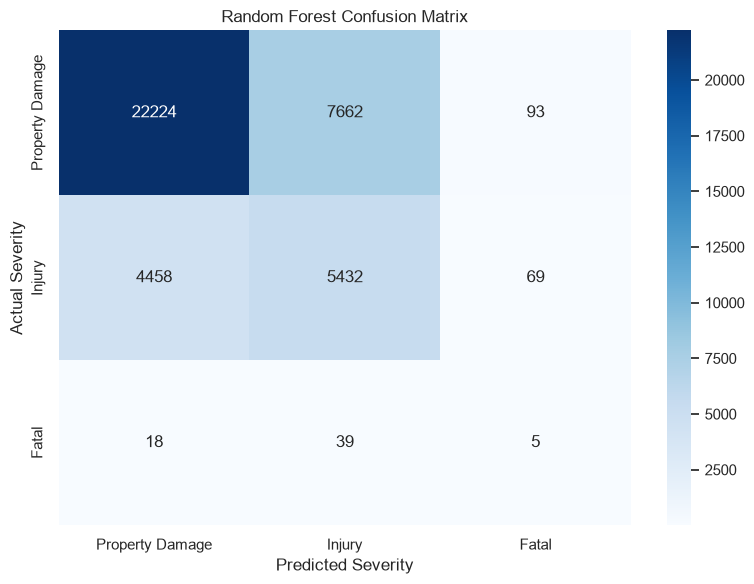

In [8]:
labels = [
    "Property Damage",
    "Injury",
    "Fatal"
]

models_to_plot = [
    ("Random Forest", rf_predictions)
]

if xgb_predictions is not None:
    models_to_plot.append(
        ("XGBoost", xgb_predictions)
    )

for model_name, predictions in models_to_plot:

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=labels
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Severity")
    plt.ylabel("Actual Severity")
    plt.tight_layout()

    safe_name = model_name.lower().replace(" ", "_")

    plt.savefig(
        CHART_DIR / f"{safe_name}_evaluation_confusion_matrix.png",
        dpi=300
    )

    plt.show()

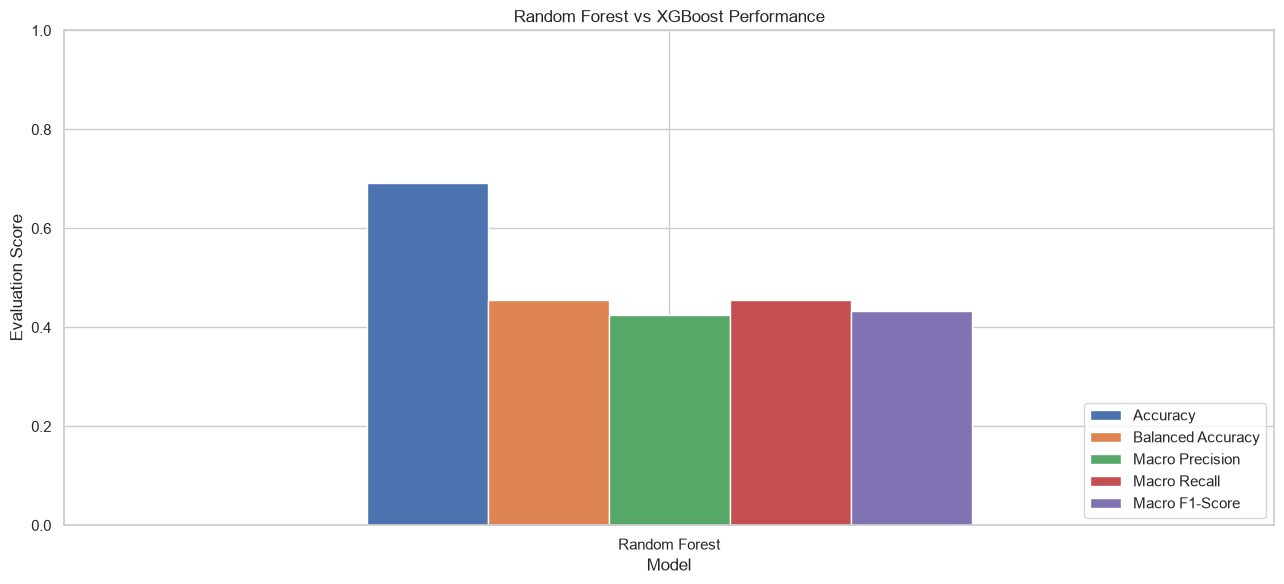

In [9]:
metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-Score"
]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Random Forest vs XGBoost Performance")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "phase6_model_comparison.png",
    dpi=300
)

plt.show()

In [10]:
comparison_df.to_csv(
    REPORT_DIR / "phase6_model_evaluation.csv",
    index=False
)

print("Evaluation report saved successfully!")
print(REPORT_DIR / "phase6_model_evaluation.csv")

Evaluation report saved successfully!
c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\visualizations\reports\phase6_model_evaluation.csv


In [11]:
best_model = comparison_df.sort_values(
    by="Macro F1-Score",
    ascending=False
).iloc[0]

print("=" * 60)
print("PHASE 6: MODEL EVALUATION SUMMARY")
print("=" * 60)

display(comparison_df)

print("\nBest model by Macro F1-Score:")
print(best_model["Model"])

print(
    "Macro F1-Score:",
    round(best_model["Macro F1-Score"], 4)
)

print("\nPhase 6 evaluation completed!")

PHASE 6: MODEL EVALUATION SUMMARY


,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Random Forest,0.691525,0.4558,0.425305,0.4558,0.43278



Best model by Macro F1-Score:
Random Forest
Macro F1-Score: 0.4328

Phase 6 evaluation completed!
